第0代發現更佳解，適應值：51377
第0代 | 最佳：51377.00 | 平均：96112.07
第1代發現更佳解，適應值：41326
第2代發現更佳解，適應值：41285
第3代發現更佳解，適應值：31207
第4代發現更佳解，適應值：21251
第5代發現更佳解，適應值：11248
第6代發現更佳解，適應值：11229
第7代發現更佳解，適應值：11204
第8代發現更佳解，適應值：11186
第9代發現更佳解，適應值：11173
第10代發現更佳解，適應值：11161
第11代發現更佳解，適應值：1186
第12代發現更佳解，適應值：1143
第14代發現更佳解，適應值：1130
第15代發現更佳解，適應值：1125
第16代發現更佳解，適應值：1103
第19代發現更佳解，適應值：1092
第20代發現更佳解，適應值：1078
第21代發現更佳解，適應值：1074
第22代發現更佳解，適應值：1061
第24代發現更佳解，適應值：1041
第25代發現更佳解，適應值：1031
第26代發現更佳解，適應值：1018
第28代發現更佳解，適應值：1009
第29代發現更佳解，適應值：1005
第30代發現更佳解，適應值：999
第31代發現更佳解，適應值：989
第32代發現更佳解，適應值：987
第33代發現更佳解，適應值：986
第34代發現更佳解，適應值：978
第35代發現更佳解，適應值：972
第37代發現更佳解，適應值：971
第39代發現更佳解，適應值：967
第40代發現更佳解，適應值：966
第41代發現更佳解，適應值：961
第43代發現更佳解，適應值：955
第44代發現更佳解，適應值：948
第45代發現更佳解，適應值：942
第47代發現更佳解，適應值：940
第49代發現更佳解，適應值：939
第50代 | 最佳：939.00 | 平均：2648.84
第51代發現更佳解，適應值：938
第53代發現更佳解，適應值：936
第54代發現更佳解，適應值：935
第56代發現更佳解，適應值：934
第58代發現更佳解，適應值：932
第59代發現更佳解，適應值：927
第62代發現更佳解，適應值：926
第80代發現更佳解，適應值：925
第88代發現更佳解，適應值：923
第93代發現更佳解，適應值：916
第94代發現更佳解，適應

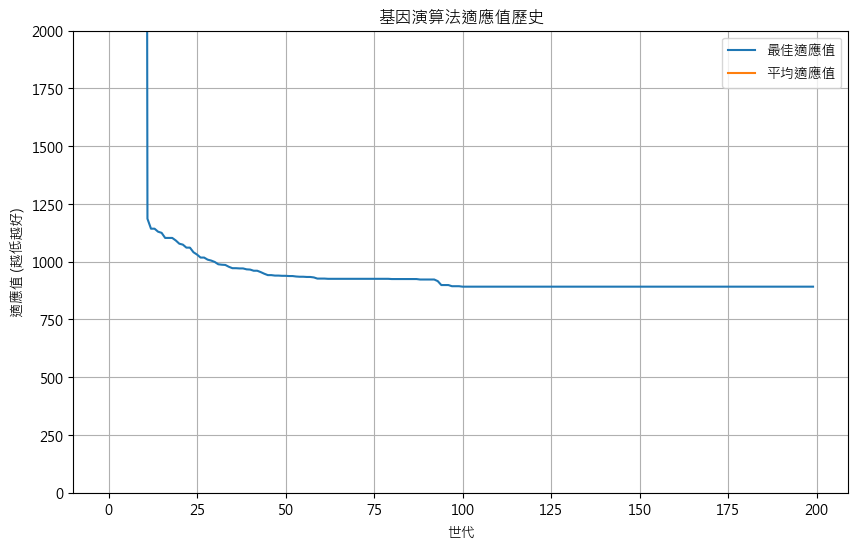


最終排程結果:
   CART_ID  ORDER WIP_ID    ACTION  COMPLETE_TIME
0      C01      1    W34    PICKUP             23
1      C01      2    W09    PICKUP             25
2      C01      3    W34  DELIVERY             51
3      C01      4    W09  DELIVERY             53
4      C07      1    W07    PICKUP              3
..     ...    ...    ...       ...            ...
75     C14      4    W14  DELIVERY             41
76     C08      1    W31    PICKUP             16
77     C08      2    W02    PICKUP             19
78     C08      3    W31  DELIVERY             31
79     C08      4    W02  DELIVERY             36

[80 rows x 5 columns]

排程結果已保存至 'schedule_result.xlsx'

排程完成！最佳適應值 (淘汰*10000+行駛距離) = 892

----- 各 CART 指標 -----
C01：淘汰訂單數 = 0, 行駛距離 = 53, 完成耗時 = 53
C02：淘汰訂單數 = 0, 行駛距離 = 36, 完成耗時 = 36
C03：淘汰訂單數 = 0, 行駛距離 = 68, 完成耗時 = 68
C04：淘汰訂單數 = 0, 行駛距離 = 51, 完成耗時 = 51
C05：淘汰訂單數 = 0, 行駛距離 = 53, 完成耗時 = 53
C06：淘汰訂單數 = 0, 行駛距離 = 35, 完成耗時 = 35
C07：淘汰訂單數 = 0, 行駛距離 = 33, 完成耗時 = 33
C08：淘汰訂單數 = 0, 行駛距離 = 36, 

In [ ]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib
from tqdm.notebook import tqdm

# 設定中文字型
matplotlib.rcParams['font.sans-serif'] = ['Microsoft JhengHei','SimHei','Arial Unicode MS']
matplotlib.rcParams['axes.unicode_minus'] = False

# -------------------------------
# 讀取資料
df_cart = pd.read_excel("data.xlsx", sheet_name="CART")
df_wip  = pd.read_excel("data.xlsx", sheet_name="WIP")
df_xfer = pd.read_excel("data.xlsx", sheet_name="XFER_TIME")

# 建立 XFER_TIME 快速查表
xfer_dict = {}
for _, row in df_xfer.iterrows():
    xfer_dict.setdefault(row["FROM"], {})[row["TO"]] = row["XFER_TIME"]

# -------------------------------
# 可調整的參數
POP_SIZE         = 200       # 族群大小
GENERATIONS      = 200        # 進化世代數
ELITE_SIZE       = 50      # 精英保留數
MUTATION_RATE    = 0.5      # 突變率
TOURNAMENT_SIZE  = 5        # 錦標賽選擇樣本數
# 裝卸耗時：設定為 0
LOAD_TIME = 0
UNLOAD_TIME = 0
# 每台 CART 一次最多接受訂單數（可調整），例如 4
BATCH_CAPACITY   = 2       
# 處理模式
MODE_SEQUENTIAL = 1  # 依序處理：對每筆訂單，先取貨再送貨（順序固定）
MODE_BATCH      = 2  # 批次模式：先全部取貨，再全部送貨（依原順序）

# -------------------------------
# 修正函式：確保每台 CART 的訂單數不超過 BATCH_CAPACITY，且每個訂單只分派一次
def repair_chromosome(chromosome):
    assigned = set()
    for cart in chromosome:
        new_list = []
        for w in chromosome[cart][0]:
            if w not in assigned and len(new_list) < BATCH_CAPACITY:
                new_list.append(w)
                assigned.add(w)
        chromosome[cart][0] = new_list
    global_orders = set(df_wip["WIP_ID"].tolist())
    missing = list(global_orders - assigned)
    random.shuffle(missing)
    for order in missing:
        added = False
        for cart in chromosome:
            if len(chromosome[cart][0]) < BATCH_CAPACITY:
                chromosome[cart][0].append(order)
                assigned.add(order)
                added = True
                break
        if not added:
            cart = random.choice(list(chromosome.keys()))
            idx = random.randrange(len(chromosome[cart][0]))
            chromosome[cart][0][idx] = order
            assigned.add(order)
    return chromosome

# -------------------------------
# 基因初始族群產生：每台 CART 的計劃：[訂單列表, 處理模式]
def init_population(pop_size):
    population = []
    wip_ids = df_wip["WIP_ID"].tolist()
    random.shuffle(wip_ids)
    cart_ids = df_cart["CART_ID"].tolist()
    base_assignment = {cart: [] for cart in cart_ids}
    for w in wip_ids:
        available = [c for c in cart_ids if len(base_assignment[c]) < BATCH_CAPACITY]
        if available:
            chosen = random.choice(available)
            base_assignment[chosen].append(w)
    for _ in range(pop_size):
        chromosome = {}
        for cart in cart_ids:
            orders_for_cart = base_assignment[cart].copy()
            random.shuffle(orders_for_cart)
            # 三種模式皆可
            mode = random.choice([MODE_SEQUENTIAL, MODE_BATCH])
            chromosome[cart] = [orders_for_cart, mode]
        population.append(chromosome)
    return population

# -------------------------------
# 用 MODE_MIXED 產生一個隨機合法的操作序列
def generate_mixed_sequence(wip_list):
    # 每個訂單擁有兩個操作 ("pickup", order) 與 ("delivery", order)
    ops = [("pickup", w) for w in wip_list] + [("delivery", w) for w in wip_list]
    attempts = 0
    while attempts < 1000:
        random.shuffle(ops)
        valid = True
        for w in wip_list:
            if ops.index(("pickup", w)) > ops.index(("delivery", w)):
                valid = False
                break
        if valid:
            return ops
        attempts += 1
    # 若無法產生，則回傳順序解
    seq = []
    for w in wip_list:
        seq.append(("pickup", w))
        seq.append(("delivery", w))
    return seq

# -------------------------------
# 評估函式：針對每台 CART 處理其所有訂單（一次性處理，數量不超過BATCH_CAPACITY）
def evaluate_cart(cart, wip_list, mode):
    init_loc = df_cart.loc[df_cart["CART_ID"]==cart, "INIT_LOC"].values[0]
    current_loc = init_loc
    time_elapsed = 0
    distance = 0
    schedule = []
    rejections = 0
    if len(wip_list) == 0:
        return 0, 0, 0, []
    # MODE_SEQUENTIAL：依序處理每筆訂單，取貨與送貨連續執行
    if mode == MODE_SEQUENTIAL:
        for wip in wip_list:
            info = df_wip.loc[df_wip["WIP_ID"]==wip].iloc[0]
            from_loc = info["FROM"]
            to_loc   = info["TO"]
            qtime    = info["Remaining Q-Time"]
            d = xfer_dict[current_loc][from_loc]
            distance += d; time_elapsed += d
            schedule.append({'wip_id': wip, 'action':'PICKUP', 'location': from_loc, 'time': time_elapsed})
            d = xfer_dict[from_loc][to_loc]
            distance += d; time_elapsed += d
            schedule.append({'wip_id': wip, 'action':'DELIVERY', 'location': to_loc, 'time': time_elapsed})
            if time_elapsed > qtime:
                rejections += 1
            current_loc = to_loc
    # MODE_BATCH：先全部取貨，再全部送貨（依原序）
    elif mode == MODE_BATCH:
        for wip in wip_list:
            info = df_wip.loc[df_wip["WIP_ID"]==wip].iloc[0]
            from_loc = info["FROM"]
            d = xfer_dict[current_loc][from_loc]
            distance += d; time_elapsed += d
            schedule.append({'wip_id': wip, 'action':'PICKUP', 'location': from_loc, 'time': time_elapsed})
            current_loc = from_loc
        for wip in wip_list:
            info = df_wip.loc[df_wip["WIP_ID"]==wip].iloc[0]
            to_loc = info["TO"]
            qtime  = info["Remaining Q-Time"]
            d = xfer_dict[current_loc][to_loc]
            distance += d; time_elapsed += d
            schedule.append({'wip_id': wip, 'action':'DELIVERY', 'location': to_loc, 'time': time_elapsed})
            if time_elapsed > qtime:
                rejections += 1
            current_loc = to_loc
    else:
        # 若模式不符，預設使用順序模式
        for wip in wip_list:
            info = df_wip.loc[df_wip["WIP_ID"]==wip].iloc[0]
            from_loc = info["FROM"]
            to_loc   = info["TO"]
            qtime    = info["Remaining Q-Time"]
            d = xfer_dict[current_loc][from_loc]
            distance += d; time_elapsed += d
            schedule.append({'wip_id': wip, 'action':'PICKUP', 'location': from_loc, 'time': time_elapsed})
            d = xfer_dict[from_loc][to_loc]
            distance += d; time_elapsed += d
            schedule.append({'wip_id': wip, 'action':'DELIVERY', 'location': to_loc, 'time': time_elapsed})
            if time_elapsed > qtime:
                rejections += 1
            current_loc = to_loc
    return rejections, distance, time_elapsed, schedule

# -------------------------------
# fitness 函式：累計所有 CART 的指標
def fitness(chromosome):
    total_rejections = 0
    total_distance = 0
    cart_details = {}
    cart_metrics = {}
    for cart, (wip_list, mode) in chromosome.items():
        wip_list = wip_list[:BATCH_CAPACITY]
        rej, dist, finish_time, sched = evaluate_cart(cart, wip_list, mode)
        total_rejections += rej
        total_distance += dist
        cart_details[cart] = sched
        cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
    fit_val = total_rejections * 10000 + total_distance
    return fit_val, cart_details, cart_metrics

# -------------------------------
# 遺傳演算法運算元：交配、突變、錦標賽選擇
def crossover(p1, p2):
    child = {}
    cart_ids = list(p1.keys())
    random.shuffle(cart_ids)
    half = len(cart_ids) // 2
    assigned = set()
    for cart in cart_ids[:half]:
        child[cart] = [p1[cart][0].copy(), p1[cart][1]]
        assigned.update(p1[cart][0])
    for cart in cart_ids[half:]:
        lst = [w for w in p2[cart][0] if w not in assigned]
        child[cart] = [lst, p2[cart][1]]
        assigned.update(lst)
    child = repair_chromosome(child)
    return child

def mutate(chromosome, mutation_rate=MUTATION_RATE):
    if random.random() > mutation_rate:
        return chromosome
    mutated = {c: [v[0].copy(), v[1]] for c,v in chromosome.items()}
    carts_list = list(mutated.keys())
    if random.random() < 0.5:
        c1, c2 = random.sample(carts_list, 2)
        if mutated[c1][0] and mutated[c2][0]:
            i = random.randrange(len(mutated[c1][0]))
            j = random.randrange(len(mutated[c2][0]))
            mutated[c1][0][i], mutated[c2][0][j] = mutated[c2][0][j], mutated[c1][0][i]
    else:
        cart = random.choice(carts_list)
        mutated[cart][1] = random.choice([MODE_SEQUENTIAL, MODE_BATCH])
    mutated = repair_chromosome(mutated)
    return mutated

def tournament_selection(population, fitness_details, k=TOURNAMENT_SIZE):
    selected = random.sample(range(len(population)), k)
    best = min(selected, key=lambda i: fitness_details[i][0])
    return population[best]

# -------------------------------
# 主 GA 流程
def genetic_algorithm(pop_size=POP_SIZE, generations=GENERATIONS, elite_size=ELITE_SIZE):
    population = init_population(pop_size)
    best_history = []
    avg_history = []
    best_solution = None
    best_fit = float('inf')
    best_details = None
    best_metrics = None

    for gen in range(generations):
        fits_details = [fitness(chrom) for chrom in population]
        fits = [fd[0] for fd in fits_details]
        details_list = [fd[1] for fd in fits_details]
        metrics_list = [fd[2] for fd in fits_details]
        
        best_idx = fits.index(min(fits))
        best_gen_fit = fits[best_idx]
        best_history.append(best_gen_fit)
        avg_history.append(sum(fits)/len(fits))
        
        if best_gen_fit < best_fit:
            best_fit = best_gen_fit
            best_solution = population[best_idx]
            best_details = details_list[best_idx]
            best_metrics = metrics_list[best_idx]
            print(f"第{gen}代發現更佳解，適應值：{best_fit}")
        
        elite_indices = sorted(range(len(fits)), key=lambda i: fits[i])[:elite_size]
        new_population = [population[i] for i in elite_indices]
        while len(new_population) < pop_size:
            parent1 = tournament_selection(population, fits_details)
            parent2 = tournament_selection(population, fits_details)
            child = crossover(parent1, parent2) if random.random() < 0.8 else parent1.copy()
            child = mutate(child)
            new_population.append(child)
        population = new_population
        
        if gen % 50 == 0:
            print(f"第{gen}代 | 最佳：{best_gen_fit:.2f} | 平均：{sum(fits)/len(fits):.2f}")
    
    plt.figure(figsize=(10,6))
    plt.plot(best_history, label="最佳適應值")
    plt.plot(avg_history, label="平均適應值")
    plt.xlabel("世代")
    plt.ylabel("適應值 (越低越好)")
    plt.title("基因演算法適應值歷史")
    plt.legend()
    plt.grid(True)
    plt.ylim(0, 2000)  # 限制 y 軸數值在 0~10000 範圍
    plt.savefig("fitness_history.png", dpi=300)
    plt.show()
    
    return best_solution, best_fit, best_details, best_metrics

# -------------------------------
# 生成排程結果，格式：[CART_ID, ORDER, WIP_ID, ACTION, COMPLETE_TIME]
def generate_schedule(details):
    output = []
    for cart, events in details.items():
        order = 1
        for ev in events:
            output.append([cart, order, ev['wip_id'], ev['action'], ev['time']])
            order += 1
    return pd.DataFrame(output, columns=["CART_ID", "ORDER", "WIP_ID", "ACTION", "COMPLETE_TIME"])

# -------------------------------
# 執行 GA 並產生排程結果
best_sol, best_fit, best_det, best_metrics = genetic_algorithm()

final_schedule = generate_schedule(best_det)
print("\n最終排程結果:")
print(final_schedule)
final_schedule.to_excel("schedule_result_1.xlsx", index=False)
print("\n排程結果已保存至 'schedule_result_1.xlsx'")
print(f"\n排程完成！最佳適應值 (淘汰*10000+行駛距離) = {best_fit}")

print("\n----- 各 CART 指標 -----")
total_rej = 0
total_dist = 0
max_time = 0
for cart in sorted(best_metrics.keys()):
    metrics = best_metrics[cart]
    total_rej += metrics["rejections"]
    total_dist += metrics["distance"]
    if metrics["completion_time"] > max_time:
        max_time = metrics["completion_time"]
    print(f"{cart}：淘汰訂單數 = {metrics['rejections']}, 行駛距離 = {metrics['distance']}, 完成耗時 = {metrics['completion_time']}")
print("\n---- 總計 ----")
print(f"總淘汰訂單數 = {total_rej}")
print(f"總行駛距離 = {total_dist}")
print(f"全部訂單完成耗時（所有 CART 中最後完成的時間） = {max_time}")